# July 2021 floods: starter notebook

This notebook does two things:
1. **Connects** you to the challenge data in the cloud. Nothing is downloaded, and no login is needed: the data is public.
2. **Shows what data is available** (EMS flood maps, EFAS flood hazard, GHS-OBAT buildings, GHS-POP population for DE, BE, NL).

Click **Run all**. Works in Colab and on a laptop.

<details>
<summary><b>Not using Colab? (VS Code, Jupyter, any Python)</b></summary>

1. `pip install gcsfs pyogrio rasterio geopandas shapely ipykernel`
   (on Windows, if that fails: `conda install -c conda-forge geopandas rasterio pyogrio gcsfs`)
2. VS Code: install the Python and Jupyter extensions and pick your environment as kernel. If the packages are already installed there, you can skip the `pip install` cell below. After installing, restart the kernel.

**Problems:** *connection or timeout errors* → check your internet connection and retry · *`No such file` on a path* → run the Explore cell to see the exact file names · *`ModuleNotFoundError`* → the kernel and your terminal use different Pythons: install with `%pip install gcsfs` inside the notebook, then restart the kernel.

</details>

## 1. Setup

In [12]:
%%capture
%pip install -q gcsfs pyogrio rasterio geopandas shapely

In [13]:
import os, re, warnings
from pathlib import Path
import pandas as pd
warnings.filterwarnings("ignore")

BUCKET = "datasets_challenge"
FOLDER = "working_data"

## 2. Connect

In [14]:
import gcsfs

# The bucket is public: no login needed.
os.environ["GS_NO_SIGN_REQUEST"] = "YES"      # lets GDAL (rasterio, pyogrio) read it anonymously
GDAL_PREFIX = "/vsigs/"
ROOT = f"{BUCKET}/{FOLDER}"
fs = gcsfs.GCSFileSystem(token="anon")
print("Connected:", [Path(p).name for p in fs.ls(ROOT)])

Connected: ['cems-efas', 'ems_be', 'ems_de', 'ems_nl', 'ghs_pop', 'obat_be', 'obat_de', 'obat_nl']


## 3. Explore

In [15]:
for folder in ["cems-efas", "ghs_pop", "obat_be", "obat_de", "obat_nl", "ems_be", "ems_de", "ems_nl"]:
    print(f"\n{folder}")
    files = fs.find(f"{ROOT}/{folder}", detail=True)
    if folder.startswith("ems_"):
        # vector products: one line per product directory
        dirs = {}
        for p, info in sorted(files.items()):
            d = dirs.setdefault(Path(p).parent.name, [0, 0])
            d[0] += p.lower().endswith(".shp"); d[1] += int(info["size"])
        for name, (n_shp, size) in dirs.items(): print("  ", name, f"{n_shp} shp, {size/1e6:,.1f} MB")
    else:
        for p, info in sorted(files.items()):
            if p.lower().endswith((".tif", ".tiff", ".gpkg")): print("  ", Path(p).name, f"{int(info['size'])/1e6:,.0f} MB")

# EMS: one row per area (aoi), type (DEL/GRA) and version, with its layers
EMS_RE = re.compile(r"(EMSR\d+)_(AOI\d+)_([A-Z]+)_(PRODUCT|MONIT\d*)_(\w+?)_r\d+_v\d+", re.I)
rows = []
for cc in ("de", "be", "nl"):
    for p in fs.find(f"{ROOT}/ems_{cc}"):
        m = EMS_RE.search(Path(p).name) if p.lower().endswith(".shp") else None
        if m: rows.append(dict(cc=cc, aoi=m[2], ptype=m[3].upper(), ver=m[4].upper(), layer=m[5]))
display(pd.DataFrame(rows).groupby(["cc", "aoi", "ptype", "ver"]).layer.apply(lambda s: ", ".join(sorted(s))).to_frame())


cems-efas
   Europe_RP100_filled_depth.tif 323 MB
   Europe_RP10_filled_depth.tif 272 MB
   Europe_RP500_filled_depth.tif 350 MB

ghs_pop
   GHS_POP_E2020_GLOBE_R2023A_4326_30ss_V1_0.tif 383 MB
   GHS_POP_E2025_GLOBE_R2023A_4326_30ss_V1_0.tif 384 MB

obat_be
   GHS_OBAT_GPKG_BEL_E2020_R2024A_V1_0.gpkg 1,433 MB

obat_de
   GHS_OBAT_GPKG_DEU_E2020_R2024A_V1_0.gpkg 8,579 MB

obat_nl
   GHS_OBAT_GPKG_NLD_E2020_R2024A_V1_0.gpkg 2,229 MB

ems_be
   EMSR518_AOI01_DEL_MONIT01_r1_VECTORS_v1_vector 9 shp, 65.4 MB
   EMSR518_AOI01_DEL_PRODUCT_r1_VECTORS_v1_vector 10 shp, 76.3 MB
   EMSR518_AOI02_DEL_MONIT01_r1_VECTORS_v1_vector 12 shp, 110.3 MB
   EMSR518_AOI02_DEL_PRODUCT_r1_VECTORS_v1_vector 10 shp, 138.3 MB

ems_de
   EMSR517_AOI01_DEL_MONIT01_r1_RTP01_v1_vector 11 shp, 21.3 MB
   EMSR517_AOI01_DEL_PRODUCT_r1_RTP01_v1_vector 10 shp, 21.3 MB
   EMSR517_AOI03_DEL_MONIT01_r1_RTP01_v1_vector 10 shp, 6.9 MB
   EMSR517_AOI03_DEL_PRODUCT_r1_RTP01_v1_vector 10 shp, 5.2 MB
   EMSR517_AOI04_DEL_MONIT01

layer
cc aoi   ptype ver                                                       
be AOI01 DEL   MONIT01  areaOfInterestA, builtUpA, facilitiesL, hydrog...
               PRODUCT  areaOfInterestA, builtUpA, facilitiesL, hydrog...
   AOI02 DEL   MONIT01  areaOfInterestA, builtUpA, facilitiesA, facili...
               PRODUCT  areaOfInterestA, facilitiesL, hydrographyA, hy...
de AOI01 DEL   MONIT01  areaOfInterestA, builtUpA, facilitiesA, facili...
               PRODUCT  areaOfInterestA, builtUpA, facilitiesL, hydrog...
   AOI03 DEL   MONIT01  areaOfInterestA, builtUpA, facilitiesA, facili...
               PRODUCT  areaOfInterestA, builtUpA, facilitiesA, facili...
   AOI04 DEL   MONIT01  areaOfInterestA, builtUpA, facilitiesA, facili...
               PRODUCT  areaOfInterestA, builtUpA, facilitiesL, hydrog...
   AOI05 DEL   MONIT01  areaOfInterestA, builtUpA, facilitiesL, hydrog...
               PRODUCT  areaOfInterestA, builtUpA, facilitiesL, hydrog...
   AOI06 DEL   MONIT01  areaOfInterestA, builtUpA, facilitiesL, hydrog...
               PRODUCT  areaOfInterestA, builtUpA, facilitiesL, hydrog...
   AOI07 GRA   PRODUCT  areaOfInterestA, builtUpP, facilitiesA, hydrog...
   AOI08 GRA   PRODUCT  areaOfInterestA, builtUpP, facilitiesA, hydrog...
   AOI09 GRA   PRODUCT  areaOfInterestA, builtUpP, facilitiesA, hydrog...
   AOI10 GRA   PRODUCT  areaOfInterestA, builtUpP, facilitiesA, facili...
   AOI11 GRA   PRODUCT  areaOfInterestA, builtUpP, facilitiesA, hydrog...
   AOI14 GRA   PRODUCT  areaOfInterestA, builtUpP, hydrographyA, hydro...
   AOI15 GRA   MONIT01  areaOfInterestA, builtUpP, facilitiesA, hydrog...
               PRODUCT  areaOfInterestA, builtUpP, facilitiesA, hydrog...
   AOI16 GRA   PRODUCT  areaOfInterestA, builtUpP, facilitiesA, hydrog...
   AOI17 GRA   PRODUCT  areaOfInterestA, builtUpP, facilitiesA, hydrog...
   AOI18 GRA   PRODUCT  areaOfInterestA, builtUpP, facilitiesA, hydrog...
   AOI20 GRA   PRODUCT  areaOfInterestA, facilitiesA, hydrographyA, hy...
nl AOI01 DEL   PRODUCT  areaOfInterestA, builtUpA, facilitiesA, hydrog...

## 4. Your analysis
Read data straight from the bucket, no login needed: list files with `fs` (gcsfs), or open them with GDAL-based libraries using the `GDAL_PREFIX` path prefix, for example `rasterio.open(f"{GDAL_PREFIX}{path}")`. The bucket is read-only, so save results to the runtime disk and download them from the file browser.

In [16]:
# your code
# Bucket name from Annex 1 / the starter notebook (it may already be in a variable there)
BUCKET = "datasets_challenge"   # <-- replace

# Top-level folders
for p in fs.ls(BUCKET):
    print(p)

datasets_challenge/starter_notebook
datasets_challenge/working_data


In [17]:
import os
from collections import defaultdict

all_files = fs.find(BUCKET)   # every file, recursively (can take a few seconds)

by_ext = defaultdict(list)
for f in all_files:
    by_ext[os.path.splitext(f)[1].lower()].append(f)

for ext, lst in sorted(by_ext.items()):
    print(f"{ext or '(no ext)'}: {len(lst)} files, e.g. {lst[0]}")

(no ext): 2 files, e.g. datasets_challenge/starter_notebook/
.dbf: 287 files, e.g. datasets_challenge/working_data/ems_be/EMSR518_AOI01_DEL_MONIT01_r1_VECTORS_v1_vector/EMSR518_AOI01_DEL_MONIT01_areaOfInterestA_r1_v1.dbf
.gpkg: 3 files, e.g. datasets_challenge/working_data/obat_be/GHS_OBAT_GPKG_BEL_E2020_R2024A_V1_0/GHS_OBAT_GPKG_BEL_E2020_R2024A_V1_0.gpkg
.ipynb: 1 files, e.g. datasets_challenge/starter_notebook/how_to_get_started.ipynb
.json: 260 files, e.g. datasets_challenge/working_data/ems_be/EMSR518_AOI01_DEL_MONIT01_r1_VECTORS_v1_vector/EMSR518_AOI01_DEL_MONIT01_areaOfInterestA_r1_v1.json
.kmz: 260 files, e.g. datasets_challenge/working_data/ems_be/EMSR518_AOI01_DEL_MONIT01_r1_VECTORS_v1_vector/EMSR518_AOI01_DEL_MONIT01_areaOfInterestA_r1_v1.kmz
.osc: 25 files, e.g. datasets_challenge/working_data/ems_be/EMSR518_AOI01_DEL_MONIT01_r1_VECTORS_v1_vector/EMSR518_AOI01_DEL_MONIT01_osmdiff_r1_v1.osc
.ovr: 2 files, e.g. datasets_challenge/working_data/ghs_pop/GHS_POP_E2020_GLOBE_R2023

In [18]:
import rasterio
from rasterio.windows import Window

raster_files = by_ext[".tif"] + by_ext[".tiff"]
path = raster_files[0]          # pick the file you need from the list above
print("Opening:", path)

with rasterio.open(f"{GDAL_PREFIX}{path}") as src:
    print("CRS:", src.crs)
    print("Size:", src.width, "x", src.height, "| bands:", src.count)
    print("Bounds:", src.bounds)
    sample = src.read(1, window=Window(0, 0, 512, 512))   # small window only
    print("Sample min/max:", sample.min(), sample.max(), "| nodata:", src.nodata)

Opening: datasets_challenge/working_data/cems-efas/Europe_RP100_filled_depth.tif
CRS: EPSG:4326
Size: 110162 x 51992 | bands: 1
Bounds: BoundingBox(left=-24.54208333, bottom=27.80708333333334, right=67.25958333666668, top=71.13375)
Sample min/max: -9999.0 -9999.0 | nodata: -9999.0


In [19]:
import geopandas as gpd

vector_files = by_ext[".shp"] + by_ext[".gpkg"] + by_ext[".geojson"]
vpath = vector_files[0]         # pick the file you need
gdf = gpd.read_file(f"{GDAL_PREFIX}{vpath}")

print(gdf.crs, len(gdf), "features")
print(gdf.columns.tolist())
display(gdf.head())

# Bucket is read-only: save to the runtime disk, then download from the file browser
gdf.to_file("my_results.gpkg", driver="GPKG")

EPSG:4326 1 features
['emsr_id', 'glide_no', 'area_id', 'locality', 'map_type', 'geometry']


,emsr_id,glide_no,area_id,locality,map_type,geometry
0,EMSR518,Not Applicable,01,Liege,Delineation-Monit01,"POLYGON ((5.82681 51.15714, 5.84045 51.14979, ..."


In [22]:
import pyogrio, pandas as pd
pd.set_option("display.max_rows", 200)

rows = []
for folder in ["ems_be", "ems_de", "ems_nl"]:
    for p in fs.find(f"{BUCKET}/{FOLDER}/{folder}"):
        if p.endswith(".shp"):
            info = pyogrio.read_info(f"{GDAL_PREFIX}{p}")
            rows.append({"pays": folder[-2:], "fichier": p.split("/")[-1],
                         "n_entites": info["features"], "geom": info["geometry_type"],
                         "path": p})
assert rows, "Aucun .shp trouvé : vérifier BUCKET/FOLDER"
inv = pd.DataFrame(rows).sort_values(["pays", "n_entites"], ascending=[True, False])
inv.to_csv("inventaire_ems.csv", index=False)
inv[["pays", "fichier", "n_entites", "geom"]]

,pays,fichier,n_entites,geom
1,be,EMSR518_AOI01_DEL_MONIT01_builtUpA_r1_v1.shp,10279,Polygon
8,be,EMSR518_AOI01_DEL_MONIT01_transportationL_r1_v...,8651,LineString
10,be,EMSR518_AOI01_DEL_PRODUCT_builtUpA_r1_v1.shp,4885,Polygon
18,be,EMSR518_AOI01_DEL_PRODUCT_transportationL_r1_v...,4418,LineString
4,be,EMSR518_AOI01_DEL_MONIT01_hydrographyL_r1_v1.shp,2993,LineString
...,...,...,...,...
256,nl,EMSR520_AOI01_DEL_PRODUCT_naturalLandUseA_r1_v...,149,Polygon
253,nl,EMSR520_AOI01_DEL_PRODUCT_hydrographyA_r1_v1.shp,14,Polygon
252,nl,EMSR520_AOI01_DEL_PRODUCT_facilitiesA_r1_v1.shp,7,Polygon
255,nl,EMSR520_AOI01_DEL_PRODUCT_imageFootprintA_r1_v...,3,Polygon


In [ ]:
%pip install folium mapclassify


   -------------------------- ------------- 2/3 [folium]
   ---------------------------------------- 3/3 [folium]

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import geopandas as gpd, folium
from pathlib import Path

def load(pays, motif):
    paths = inv.loc[(inv.pays == pays) & inv.fichier.str.contains(motif, case=False), "path"]
    return pd.concat([gpd.read_file(f"{GDAL_PREFIX}{p}").to_crs(4326) for p in paths],
                     ignore_index=True)

flood = load("be", "observed")   # adjust to the flood-extent file name seen in the inventory
aoi   = load("be", "area")       # same for the area of interest
flood["geometry"] = flood.simplify(0.0001)  # lighter display

m = aoi.explore(color="black", style_kwds={"fill": False}, name="Mapped area (AOI)")
flood.explore(m=m, color="royalblue", name="Observed water (satellite snapshot)")
folium.LayerControl().add_to(m)

# Save next to the notebook (VS Code), otherwise in the current folder
nb_dir = Path(globals()["__vsc_ipynb_file__"]).parent if "__vsc_ipynb_file__" in globals() else Path.cwd()
out = nb_dir / "carte_be.html"
m.save(out)
print("Map saved to:", out)
m

Surface d'eau observée (BE, AOI cartographiées) : 53.3 km²


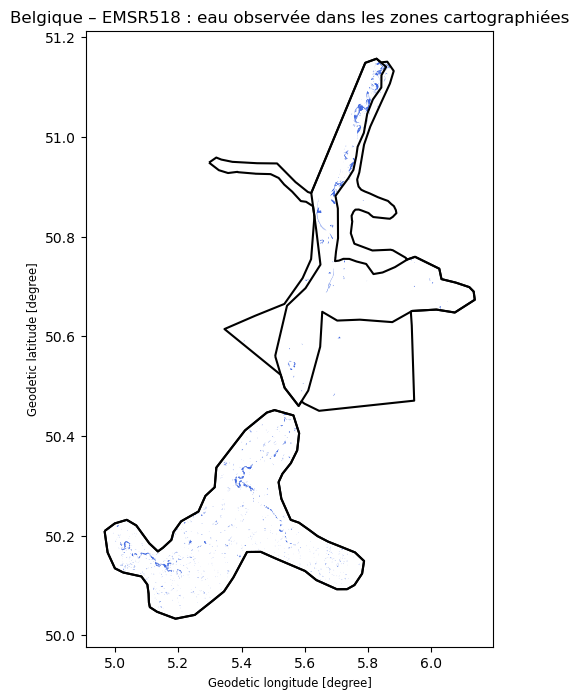

In [ ]:
area_km2 = flood.to_crs(3035).area.sum() / 1e6   # EPSG:3035, projection en mètres pour l'Europe
print(f"Surface d'eau observée (BE, AOI cartographiées) : {area_km2:.1f} km²")

ax = aoi.boundary.plot(color="black", figsize=(8, 8))
flood.plot(ax=ax, color="royalblue")
ax.set_title("Belgique – EMSR518 : eau observée dans les zones cartographiées")
ax.figure.savefig("fig_be.png", dpi=200, bbox_inches="tight")

In [24]:
import geopandas as gpd, pandas as pd
from pathlib import Path

# 1. Load observed water (no simplification), keeping the source product, plus the AOI
def load_be(motif):
    paths = inv.loc[(inv.pays == "be") & inv.fichier.str.contains(motif, case=False), "path"]
    return pd.concat([gpd.read_file(f"{GDAL_PREFIX}{p}").to_crs(3035).assign(produit=p.split("/")[-2])
                      for p in paths], ignore_index=True)

f = load_be("observed")
a = load_be("areaOfInterest")
nb_dir = Path(globals()["__vsc_ipynb_file__"]).parent if "__vsc_ipynb_file__" in globals() else Path.cwd()
f["surface_ha"] = f.area / 1e4

# 2. Global stats
union_ha = f.union_all().area / 1e4   # union = no double counting across products
print(f"Polygons: {len(f)} | products: {f.produit.nunique()}")
print(f"Raw sum: {f.surface_ha.sum():,.0f} ha | real area (union): {union_ha:,.0f} ha")
display(f.groupby("produit").surface_ha.agg(["count", "sum", "median", "max"]).round(1))

# 3. Size distribution
display(f.surface_ha.describe(percentiles=[.1, .25, .5, .75, .9, .99]).round(2))
top10 = f.surface_ha.nlargest(max(1, len(f) // 10)).sum() / f.surface_ha.sum()
print(f"Largest 10% of polygons = {top10:.0%} of total area")

# 4. Flooded share per AOI
a["aoi"] = a["locality"] if "locality" in a.columns else a.index.astype(str)
a = a.dissolve("aoi").reset_index()
inter = gpd.overlay(gpd.GeoDataFrame(geometry=[f.union_all()], crs=3035), a[["aoi", "geometry"]])
par_aoi = pd.DataFrame({"aoi_ha": a.set_index("aoi").area / 1e4,
                        "eau_ha": inter.dissolve("aoi").area / 1e4}).fillna(0)
par_aoi["part_inondee_%"] = 100 * par_aoi.eau_ha / par_aoi.aoi_ha
display(par_aoi.round(1))

# 5. Breakdown by size class (table)
classes = pd.cut(f.surface_ha, bins=[0, 0.1, 1, 10, 100, float("inf")],
                 labels=["< 0.1 ha", "0.1–1 ha", "1–10 ha", "10–100 ha", "> 100 ha"])
taille = f.groupby(classes, observed=False).surface_ha.agg(n_polygones="count", surface_ha="sum")
taille["%_polygones"] = 100 * taille.n_polygones / taille.n_polygones.sum()
taille["%_surface"] = 100 * taille.surface_ha / taille.surface_ha.sum()
display(taille.round(1))

# 6. Export for the team
par_aoi.to_csv(nb_dir / "stats_aoi_be.csv")
taille.to_csv(nb_dir / "classes_taille_be.csv")
f.drop(columns="geometry").to_csv(nb_dir / "polygones_be.csv", index=False)
print("Files saved in:", nb_dir)

Polygons: 2020 | products: 4
Raw sum: 5,347 ha | real area (union): 2,973 ha


,count,sum,median,max
produit,,,,
EMSR518_AOI01_DEL_MONIT01_r1_VECTORS_v1_vector,390,1996.8,1.4,120.4
EMSR518_AOI01_DEL_PRODUCT_r1_VECTORS_v1_vector,151,752.5,1.5,81.1
EMSR518_AOI02_DEL_MONIT01_r1_VECTORS_v1_vector,1195,1766.8,0.6,40.1
EMSR518_AOI02_DEL_PRODUCT_r1_VECTORS_v1_vector,284,830.9,0.9,40.1


count    2020.00
mean        2.65
std         6.99
min         0.00
10%         0.30
25%         0.41
50%         0.77
75%         1.91
90%         5.48
99%        36.96
max       120.39
Name: surface_ha, dtype: float64

Largest 10% of polygons = 63% of total area


,aoi_ha,eau_ha,part_inondee_%
aoi,,,
Liege,159712.2,1399.1,0.9
Rochefort,105474.4,1573.9,1.5


,n_polygones,surface_ha,%_polygones,%_surface
surface_ha,,,,
< 0.1 ha,4,0.2,0.2,0.0
0.1–1 ha,1156,573.1,57.2,10.7
1–10 ha,755,2156.8,37.4,40.3
10–100 ha,103,2384.8,5.1,44.6
> 100 ha,2,232.0,0.1,4.3


Files saved in: c:\Users\danuk\OneDrive\Documents\ai challenge
